<h1> TP3 - Performance d'un classifieur</h1>

<h2> Introduction </h2>

La détection de peau dans les images est une étape importante pour pas mal d'applications en vision par ordinateur, notamment pour la détection de visages. Dans ce TP, on s'intéresse à la classification de pixels selon leur teinte (peau ou non-peau) en utilisant les composantes de chrominance Cb et Cr de l'espace colorimétrique YCbCr.
L'objectif est de comparer deux approches de modélisation probabiliste : une première avec des dimensions décorrélées (hypothèse d'indépendance entre Cb et Cr) et une seconde prenant en compte la corrélation complète entre ces composantes. On travaille sur la base d'images Pratheepan Dataset qui contient des images annotées manuellement.


Le TP se déroule en quatre parties : d'abord le chargement et la visualisation des données, ensuite la modélisation avec une loi normale 2D décorrélée, puis avec une loi normale 2D complète, et enfin un test sur une nouvelle image.

<h2> Ajout du code fourni et import des librairies nécessaires </h2>

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from scipy.stats import multivariate_normal, norm
from PIL import Image

DATA_PATH = 'Data/'

image_ext = ['.jpg']
images =  [os.path.join(DATA_PATH, f) for f in os.listdir(DATA_PATH) if f.endswith(".jpg")]

X_train=np.empty((0, 2))
y_train=[]
for name in images[0:-4]:
    I= Image.open(name)
    I = I.convert('YCbCr')
    I = np.array(I)
    I=np.reshape(I[:,:,1:3],[I.shape[0]*I.shape[1],2])
    X_train = np.concatenate((X_train, I), axis=0)
    fichier_png= os.path.splitext(name)[0] + ".png"
    GT = Image.open(fichier_png)
    GT = np.array(GT)
    GT=np.reshape(GT[:,:,1]/255,[GT.shape[0]*GT.shape[1]])
    y_train = np.concatenate((y_train, GT), axis=0)


X_test=np.empty((0, 2))
y_test=[]
for name in images[-4:]:
    I= Image.open(name)
    I = I.convert('YCbCr')
    I = np.array(I)
    I=np.reshape(I[:,:,1:3],[I.shape[0]*I.shape[1],2])
    X_test = np.concatenate((X_test, I), axis=0)
    fichier_png= os.path.splitext(name)[0] + ".png"
    GT = Image.open(fichier_png)
    GT = np.array(GT)
    GT=np.reshape(GT[:,:,1]/255,[GT.shape[0]*GT.shape[1]])
    y_test = np.concatenate((y_test, GT), axis=0)

X_train = X_train.astype('float64')
X_test = X_test.astype('float64')

X_train, pipo, y_train, pipo = train_test_split(X_train, y_train, train_size=1/1000, random_state=247)
X_test, pipo, y_test, pipo = train_test_split(X_test, y_test, train_size=1/1000, random_state=247)



<h2> I. Chargement et visualisation des données </h2>

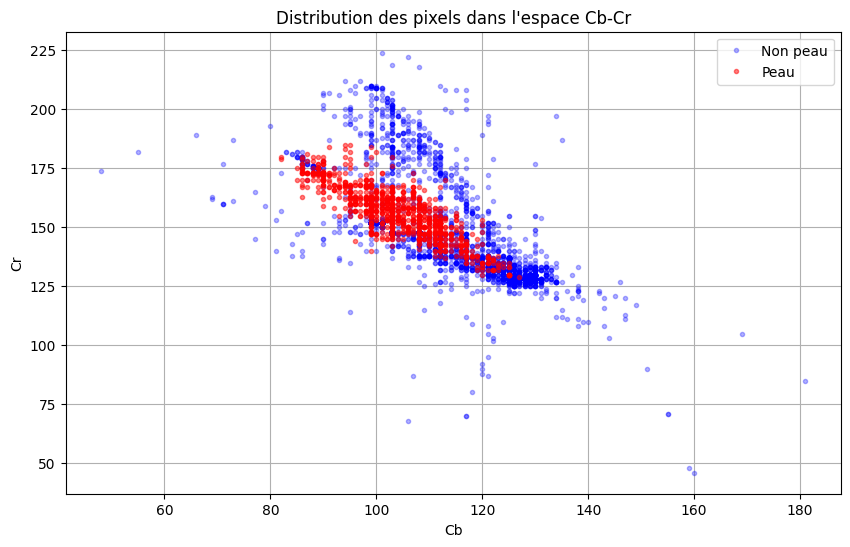

In [19]:
# Séparation pixels peau / non peau
Peau_Train = X_train[np.where(y_train==1),:]
Peau_Train = np.reshape(Peau_Train, (Peau_Train.shape[1], Peau_Train.shape[2]))

Nonpeau_Train = X_train[np.where(y_train==0),:]
Nonpeau_Train = np.reshape(Nonpeau_Train, (Nonpeau_Train.shape[1], Nonpeau_Train.shape[2]))


# Visualisation
plt.figure(figsize=(10, 6))
plt.plot(Nonpeau_Train[:,0], Nonpeau_Train[:,1], '.b', label='Non peau', alpha=0.3)
plt.plot(Peau_Train[:,0], Peau_Train[:,1], '.r', label='Peau', alpha=0.5)
plt.xlabel('Cb')
plt.ylabel('Cr')
plt.title('Distribution des pixels dans l\'espace Cb-Cr')
plt.legend()
plt.grid(True)
plt.show()


<h3>Questions</h3>

Réponses aux questions I.

In [20]:
print(f"\nTaille base d'apprentissage : {X_train.shape}")
print(f"Taille base de test : {X_test.shape}")
print(f"Dimension des données : {X_train.shape[1]}")
print(f"Nombre de classes : 2 (peau / non peau)")
print(f"Exemples classe 'peau' (train) : {Peau_Train.shape[0]}")
print(f"Exemples classe 'non peau' (train) : {Nonpeau_Train.shape[0]}")


Taille base d'apprentissage : (4636, 2)
Taille base de test : (669, 2)
Dimension des données : 2
Nombre de classes : 2 (peau / non peau)
Exemples classe 'peau' (train) : 1106
Exemples classe 'non peau' (train) : 3530


Pour la base d'apprentissage, 4636 est le nombre de pixels dans la base d'apprentissage et pour la base de test, 669 est le nombre de pixels dans la base de test.

Afin d'avoir des temps de calcul raisonnables, on conservera pour la suite 1 pixel sur 1000 pour les bases d'apprentissage et de test. Pour reproductibilité lors de la correction, la variable random_state correspondra aux trois derniers chiffres de mon numéro d'étudiant.

<h2>II. Modélisation de la vraissemblance des observations par une loi normale 2D avec des dimensions décorrélées</h2>

Comme il est difficile de modéliser tout ce qui n'est pas teinte chaire, on décide de travailler avec une seule classe, la teinte chaire, dont on estime la vraissemblance des observations p(x/chair).

<h3> a. Estimation de la vraissemblance des observatiosn des pixels de teinte chaire </h3>

<h3> Réponses aux questions </h3>

- Les variables sont indicées par Cb et Cr parce que Cb et Cr sont les composantes de chrominance dans l'espace YCbCr.

- Les dimensions de mCb, mCr, σCb, σCr sont:

In [21]:
mcb = np.mean(Peau_Train[:,0])
mcr = np.mean(Peau_Train[:,1])
scb = np.std(Peau_Train[:,0])
scr = np.std(Peau_Train[:,1])

print(f"mCb = {mcb:.2f}")
print(f"mCr = {mcr:.2f}")
print(f"σCb = {scb:.2f}")
print(f"σCr = {scr:.2f}")

mCb = 103.74
mCr = 156.42
σCb = 8.69
σCr = 10.81


<p>On va estimer la vraissemblance des observations p(x/chair) sur les bases d'apprentissage et de test qu'on va stocker dans p_train et p_test</p>

In [22]:
p1 = norm(mcb, scb)
p2 = norm(mcr, scr)
p_train = p1.pdf(X_train[:,0]) * p2.pdf(X_train[:,1])
p_test = p1.pdf(X_test[:,0]) * p2.pdf(X_test[:,1])


<h3>Réponses aux questiosn </h3>

In [24]:
print(f"\nDimension de p(x/chair) pour un pixel : scalaire")
print(f"Dimension de p_train : {p_train.shape}")
print(f"Hypothèse : Les dimensions Cb et Cr sont indépendantes")


Dimension de p(x/chair) pour un pixel : scalaire
Dimension de p_train : (4636,)
Hypothèse : Les dimensions Cb et Cr sont indépendantes


<h3>b. Mise en place du classifieur</h3>

Pour réaliser la classification, on va seuiller la vraissemblance des observatiosn p(x/chair) de la base de test.

N'ayant aucune idée du seuil à utiliser, on met le classifieur au point sur la base d'apprentissage. En utilisant comme seuil la valeur moyenne de p_train, estimons sur la base d'apprentissage:

- TP: le nombre de vrai positif
- TN: le nombre de vrai négatif
- FP: le nombre de faux positif
- FN: le nombre de faux négatif

In [25]:
seuil_initial = np.mean(p_train)

y_pred_train = (p_train >= seuil_initial).astype(int)

TP = np.sum((y_pred_train == 1) & (y_train == 1))
TN = np.sum((y_pred_train == 0) & (y_train == 0))
FP = np.sum((y_pred_train == 1) & (y_train == 0))
FN = np.sum((y_pred_train == 0) & (y_train == 1))


print(f"\nAvec seuil = {seuil_initial:.6f}")
print(f"TP (vrai positif) = {TP}")
print(f"TN (vrai négatif) = {TN}")
print(f"FP (faux positif) = {FP}")
print(f"FN (faux négatif) = {FN}")


Avec seuil = 0.000434
TP (vrai positif) = 839
TN (vrai négatif) = 2737
FP (faux positif) = 793
FN (faux négatif) = 267


Maintenant, estimons la sensibilité et la spécificité.

In [26]:
sensibilite = TP / (TP + FN)
specificite = TN / (TN + FP)

print(f"Sensibilité = {sensibilite:.3f}")
print(f"Spécificité = {specificite:.3f}")

Sensibilité = 0.759
Spécificité = 0.775


Déterminons le taux de bonne reconnaissance avec ce seuil

In [27]:
taux_recon = (TP + TN) / (TP + TN + FP + FN)
print(f"Taux de bonne reconnaissance = {taux_recon:.3f}")

Taux de bonne reconnaissance = 0.771


<h3>Réponses aux questions</h3>

- TP: pixels peau correctement classés comme peau
- TN: pixels non-peau correctement classés comme non-peau
- FP: pixels non-peau incorrectement classés comme peau
- FN: pixels peau incorrectement classés comme non-peau
- Sensibilité = TP/(TP+FN), Spécificité = TN/(TN+FP)
- Taux = (TP+TN)/(TP+TN+FP+FN)
- Seuil choisi car c'est une première estimation raisonnable

<h3> c. Courbe ROC </h3>

Plutôt que de choisir un seuil arbitraire, on choisit 20 valeurs de seuils régulièrement réparties entre min(p_train) et max(p_train). Pour chaque valeur de seuil, on va estimer la précision et le rappel et tracer la courbe ROC.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


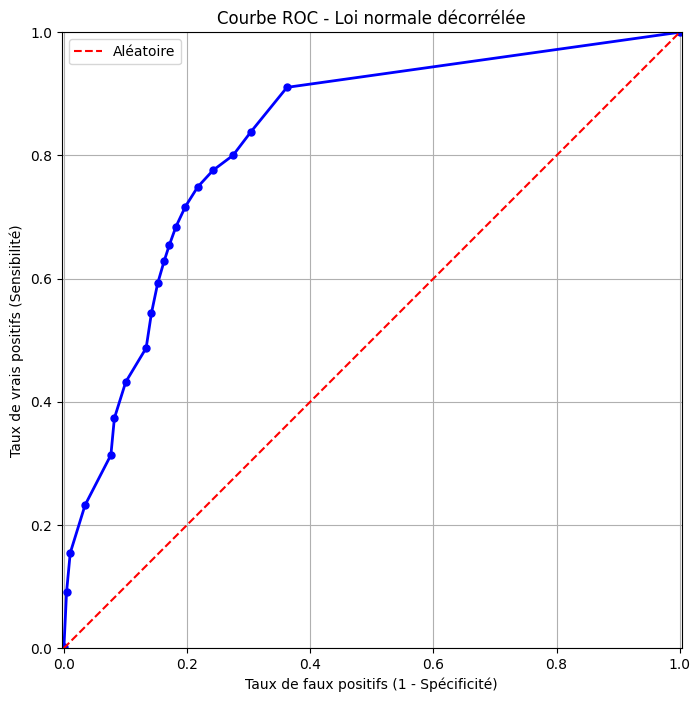

In [28]:
NB = 20
SEUILS = np.linspace(np.min(p_train), np.max(p_train), NB)

tpr_list = []  # Taux de vrais positifs (rappel)
fpr_list = []  # Taux de faux positifs

for seuil in SEUILS:
    y_pred = (p_train >= seuil).astype(int)
    
    TP = np.sum((y_pred == 1) & (y_train == 1))
    TN = np.sum((y_pred == 0) & (y_train == 0))
    FP = np.sum((y_pred == 1) & (y_train == 0))
    FN = np.sum((y_pred == 0) & (y_train == 1))
    
    tpr = TP / (TP + FN) if (TP + FN) > 0 else 0
    fpr = FP / (FP + TN) if (FP + TN) > 0 else 0
    
    tpr_list.append(tpr)
    fpr_list.append(fpr)

plt.figure(figsize=(8, 8))
plt.plot(fpr_list, tpr_list, 'bo-', linewidth=2, markersize=5)
plt.plot([0, 1], [0, 1], 'r--', label='Aléatoire')
plt.xlabel('Taux de faux positifs (1 - Spécificité)')
plt.ylabel('Taux de vrais positifs (Sensibilité)')
plt.title('Courbe ROC - Loi normale décorrélée')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.show()

<h3>Réponses aux questions</h3>

In [29]:
diff = np.abs(np.array(tpr_list) - np.array(fpr_list))
idx_equilibre = np.argmin(diff)
seuil_equilibre = SEUILS[idx_equilibre]

print(f"\nPoint de fonctionnement trouvé :")
print(f"Seuil = {seuil_equilibre:.6f}")
print(f"TPR = {tpr_list[idx_equilibre]:.3f}")
print(f"FPR = {fpr_list[idx_equilibre]:.3f}")

y_pred_equilibre = (p_train >= seuil_equilibre).astype(int)
taux_equilibre = np.mean(y_pred_equilibre == y_train)
print(f"Taux de reconnaissance = {taux_equilibre:.3f}")


Point de fonctionnement trouvé :
Seuil = 0.000000
TPR = 1.000
FPR = 1.000
Taux de reconnaissance = 0.239


<h3>d. Classification dex pixels de test</h3>

Avec ce seuil, déterminons le taux de bonne classification des pixels de test.

In [30]:
y_pred_test = (p_test >= seuil_equilibre).astype(int)
taux_test = np.mean(y_pred_test == y_test)
print(f"\nTaux de bonne classification sur test = {taux_test:.3f}")


Taux de bonne classification sur test = 0.389


<h2>III. Modélisation de la vraissemblance des observations par une loi normale 2D</h2>

Reprenons la partie II. en utilisant une loi normale 2D.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.



Moyenne m :
[103.74050633 156.42314647]

Matrice de covariance :
[[ 75.5805659  -79.1941692 ]
 [-79.1941692  116.93933706]]


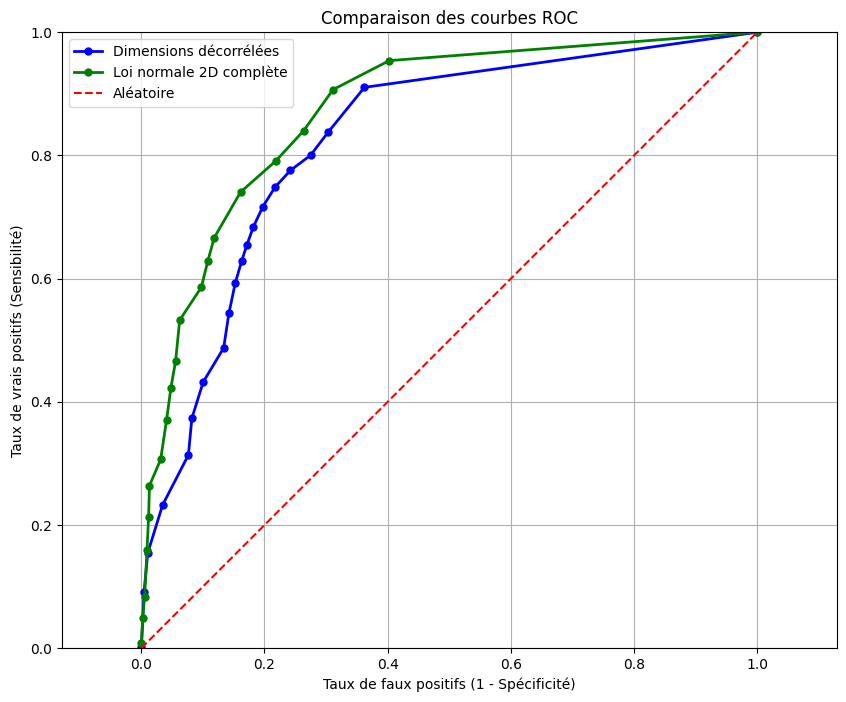

In [31]:
#

In [33]:
# Calcul AUC approximatif
auc1 = np.trapz(tpr_list, fpr_list)
auc2 = np.trapz(tpr_list2, fpr_list2)

print(f"\nAUC méthode 1 (décorrélée) : {abs(auc1):.3f}")
print(f"AUC méthode 2 (complète) : {abs(auc2):.3f}")



AUC méthode 1 (décorrélée) : 0.825
AUC méthode 2 (complète) : 0.873


/tmp/ipykernel_709872/1532845517.py:2: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc1 = np.trapz(tpr_list, fpr_list)
/tmp/ipykernel_709872/1532845517.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc2 = np.trapz(tpr_list2, fpr_list2)


La loi normale 2D complète donne de meilleurs résultats
car elle prend en compte la corrélation entre Cb et Cr

<h3>Réponses aux questiosn</h3>

La méthode qui amène aux meilleurs résultats est celle avec la loi normale 2D

<h2>IV. Test sur une nouvelle image</h3>

Réalisons la détection des pixels de teinte chaire sur l'image "image.jpg".

Taille image : 500 x 885
Statistiques Cb image : min=91.0, max=191.0, mean=125.4
Statistiques Cr image : min=60.0, max=170.0, mean=130.3

Statistiques p_image : min=1.22e-32, max=3.13e-03, mean=4.06e-04
Seuil équilibré utilisé : 1.34e-50
Seuil adaptatif (70ème percentile) : 1.23e-04
Nombre de pixels classés comme peau : 134113 (30.3%)


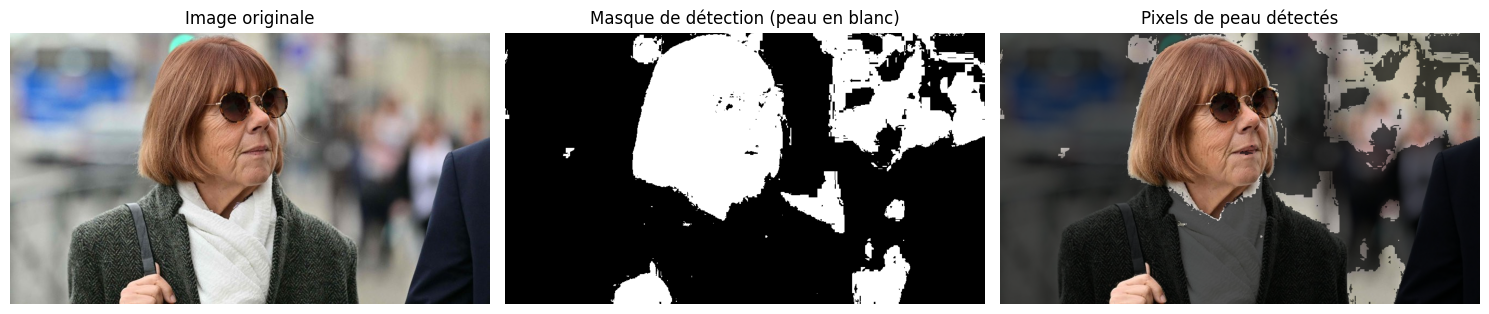

In [37]:
# Chargement de l'image
img = Image.open('image.jpg')
img_ycbcr = img.convert('YCbCr')
img_array = np.array(img_ycbcr)

# Extraction des composantes Cb et Cr
h, w = img_array.shape[0], img_array.shape[1]
X_image = img_array[:,:,1:3].reshape(h*w, 2).astype('float64')

print(f"Taille image : {h} x {w}")
print(f"Statistiques Cb image : min={X_image[:,0].min():.1f}, max={X_image[:,0].max():.1f}, mean={X_image[:,0].mean():.1f}")
print(f"Statistiques Cr image : min={X_image[:,1].min():.1f}, max={X_image[:,1].max():.1f}, mean={X_image[:,1].mean():.1f}")

# Classification avec la loi normale 2D complète
p_image = p.pdf(X_image)

print(f"\nStatistiques p_image : min={p_image.min():.2e}, max={p_image.max():.2e}, mean={p_image.mean():.2e}")
print(f"Seuil équilibré utilisé : {seuil_equilibre2:.2e}")

# IMPORTANT : Utiliser un percentile plutôt qu'un seuil fixe
# On prend les 30% de pixels les plus probables d'être de la peau
seuil_adaptatif = np.percentile(p_image, 70)  # 70ème percentile
print(f"Seuil adaptatif (70ème percentile) : {seuil_adaptatif:.2e}")

y_pred_image = (p_image >= seuil_adaptatif).astype(int)
mask = y_pred_image.reshape(h, w)

print(f"Nombre de pixels classés comme peau : {np.sum(mask)} ({100*np.sum(mask)/(h*w):.1f}%)")

# Affichage des résultats
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img)
axes[0].set_title('Image originale')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Masque de détection (peau en blanc)')
axes[1].axis('off')

# Superposition
img_result = np.array(img).copy()
img_result[mask == 0] = img_result[mask == 0] // 3
axes[2].imshow(img_result)
axes[2].set_title('Pixels de peau détectés')
axes[2].axis('off')

plt.tight_layout()
plt.show()


<h2>Conclusion</h2>

Ce TP m'a permis de comprendre concrètement comment évaluer les performances d'un classifieur binaire. Les points importants que je retiens sont :

L'importance du choix du modèle : même si l'hypothèse d'indépendance simplifie les calculs, prendre en compte la corrélation améliore sensiblement les résultats. Dans notre cas, la loi normale 2D complète est meilleure que le modèle décorrélé.

La courbe ROC est un outil essentiel : elle permet de choisir le seuil optimal selon les besoins de l'application. Par exemple, pour la détection de visages, on pourrait préférer une haute sensibilité (ne pas rater de visages) quitte à avoir plus de faux positifs.

Les métriques complémentaires : TP, TN, FP, FN, sensibilité et spécificité donnent une vision beaucoup plus complète qu'un simple taux de reconnaissance global. C'est crucial quand les classes sont déséquilibrées.

La validation sur un jeu de test : indispensable pour vérifier que le modèle généralise bien et ne sur-apprend pas sur les données d'apprentissage.